# 02 · Tracking validation

How good is broadcast tracking, and what does smoothing actually change? Both questions answered from the raw frames.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config as C
pd.set_option("display.width", 160, "display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110})
E = C.PROCESSED_DIR / "events"; D = C.DERIVED_DIR
rd  = lambda n: pd.read_parquet(D / f"{n}.parquet")
rev = lambda n: pd.read_parquet(E / f"{n}.parquet")
print("project:", C.PROJECT_ROOT.name)

project: basketball-intelligence


## Detection and prediction error, per game

These reproduce SkillCorner's own published ranges (76–83 % detected, 1.5–1.9 ft mean error) from an independent computation.

In [2]:
tq = rd("tracking_quality")
print(f"detected: {tq.pct_detected.min():.1f}–{tq.pct_detected.max():.1f} %")
print(f"mean predError: {tq.mean_pred_error.min():.2f}–{tq.mean_pred_error.max():.2f} ft")
print(f"  detected {tq.mean_pred_error_detected.mean():.2f} ft | "
      f"extrapolated {tq.mean_pred_error_extrapolated.mean():.2f} ft")
tq[["game_id","frames","pct_detected","mean_pred_error","p95_pred_error",
    "mean_pred_error_detected","mean_pred_error_extrapolated","pct_rows_in_possession"]].round(2)

detected: 76.2–82.8 %
mean predError: 1.52–1.86 ft
  detected 0.88 ft | extrapolated 4.75 ft


,game_id,frames,pct_detected,mean_pred_error,p95_pred_error,mean_pred_error_detected,mean_pred_error_extrapolated,pct_rows_in_possession
0,114086,92188,80.68,1.52,4.90,0.84,4.36,97.03
1,114099,75655,81.68,1.58,5.26,0.88,4.72,98.68
2,114169,106176,76.17,1.86,6.28,0.90,4.92,98.32
3,114234,72132,82.76,1.63,5.12,0.89,5.15,97.97
4,114243,77023,82.65,1.56,4.88,0.91,4.63,99.05
5,178442,89642,80.31,1.60,5.27,0.88,4.57,97.11
6,179612,83437,78.86,1.72,5.73,0.91,4.76,98.24
7,184439,77428,81.50,1.61,5.30,0.88,4.85,98.22
8,188630,73138,80.64,1.57,5.17,0.86,4.52,98.15
9,191313,82885,79.28,1.75,5.84,0.88,5.08,99.28


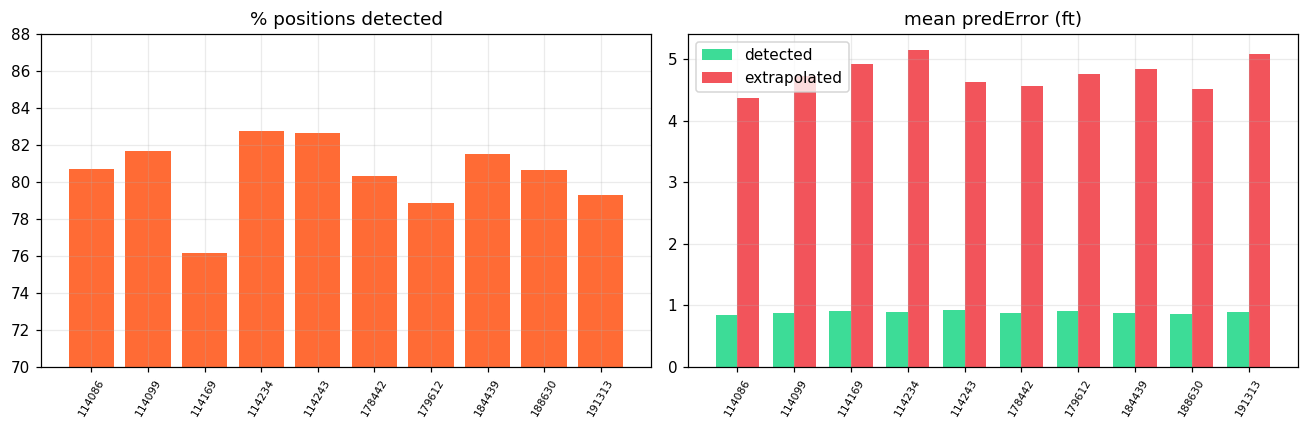

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(len(tq)), tq.pct_detected, color="#FF6B35")
ax[0].set_ylim(70, 88); ax[0].set_title("% positions detected"); ax[0].set_xticks(range(len(tq)))
ax[0].set_xticklabels(tq.game_id, rotation=60, fontsize=7)
w = .38; x = np.arange(len(tq))
ax[1].bar(x-w/2, tq.mean_pred_error_detected, w, label="detected", color="#3DDC97")
ax[1].bar(x+w/2, tq.mean_pred_error_extrapolated, w, label="extrapolated", color="#F2545B")
ax[1].set_title("mean predError (ft)"); ax[1].legend()
ax[1].set_xticks(x); ax[1].set_xticklabels(tq.game_id, rotation=60, fontsize=7)
plt.tight_layout(); plt.show()

## Raw versus smoothed kinematics

The headline: the delivered positions are already temporally smooth. Our Savitzky–Golay filter clips the tail and changes nothing else.

In [4]:
sm = rd("smoothing_report")
print(sm[["game_id","raw_mean_speed","smoothed_mean_speed","raw_p99_speed","smoothed_p99_speed",
          "raw_max_speed","smoothed_max_speed","corr_raw_with_delivered"]].round(3).to_string(index=False))
print(f"\ncorrelation of RAW central-difference speed with SkillCorner's own `speed` field: "
      f"{sm.corr_raw_with_delivered.mean():.4f}")
print(f"max speed {sm.raw_max_speed.max():.1f} -> {sm.smoothed_max_speed.max():.1f} ft/s")

 game_id  raw_mean_speed  smoothed_mean_speed  raw_p99_speed  smoothed_p99_speed  raw_max_speed  smoothed_max_speed  corr_raw_with_delivered
  114086           4.928                4.917         16.925              16.912         50.094              30.489                    0.999
  114099           5.555                5.547         17.412              17.399         31.792              24.418                    0.999
  114169           4.493                4.482         16.991              16.966         46.001              29.406                    0.999
  114234           5.895                5.887         17.972              17.963         47.803              30.364                    0.999
  114243           5.933                5.925         18.604              18.586         98.131              48.012                    0.999
  178442           5.335                5.326         16.819              16.803         42.084              29.705                    0.999
  179612     

## One player, one possession: what the filter does

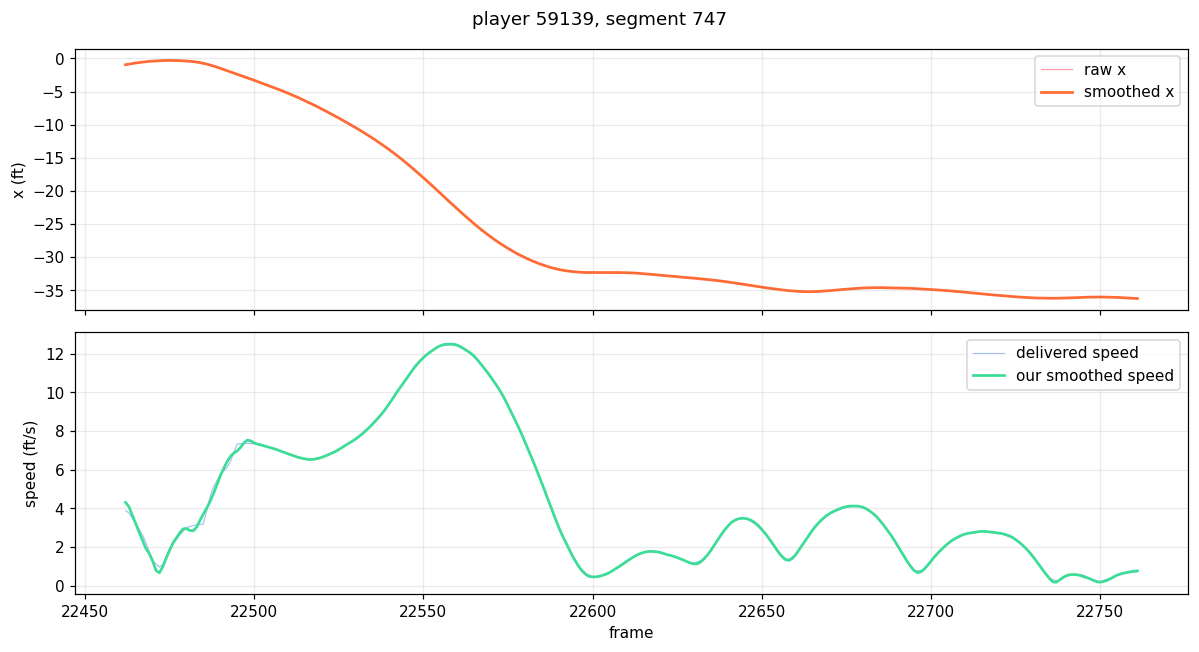

In [5]:
from src.tracking import engine
gid = int(tq.game_id.iloc[0])
t = pd.read_parquet(C.PROCESSED_DIR / f"tracking_enriched/{gid}.parquet")
seg = t[t.speed.notna()].groupby(["player_id","segment_id"]).size().sort_values()
pid, sid = seg.index[len(seg)//2]
w = t[(t.player_id == pid) & (t.segment_id == sid)].head(300)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(w.frame_idx, w.x, lw=.8, alpha=.55, label="raw x", color="#F2545B")
ax[0].plot(w.frame_idx, w.x_s, lw=1.8, label="smoothed x", color="#FF6B35")
ax[0].set_ylabel("x (ft)"); ax[0].legend()
ax[1].plot(w.frame_idx, w.speed_raw, lw=.8, alpha=.55, label="delivered speed", color="#5B8DEF")
ax[1].plot(w.frame_idx, w.speed, lw=1.8, label="our smoothed speed", color="#3DDC97")
ax[1].set_ylabel("speed (ft/s)"); ax[1].set_xlabel("frame"); ax[1].legend()
plt.suptitle(f"player {pid}, segment {sid}"); plt.tight_layout(); plt.show()

## Speed distribution and the movement bands

count    921880.00
mean          4.92
std           4.09
min           0.00
50%           3.70
90%          11.22
99%          16.91
99.9%        20.49
max          30.49
Name: speed, dtype: float64


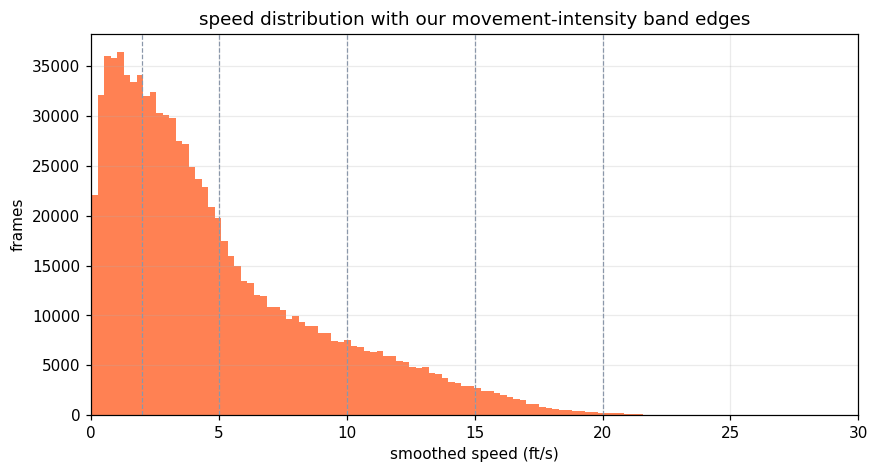

speed_band
walking       0.3464
standing      0.2813
jogging       0.2370
running       0.1080
high_speed    0.0258
sprinting     0.0015
Name: proportion, dtype: float64


In [6]:
sp = t.speed.dropna()
print(sp.describe(percentiles=[.5,.9,.99,.999]).round(2))
plt.hist(sp, bins=120, color="#FF6B35", alpha=.85)
for _, lo, hi in C.SPEED_BANDS[:-1]:
    plt.axvline(hi, color="#8A97AA", lw=.8, ls="--")
plt.xlim(0, 30); plt.xlabel("smoothed speed (ft/s)"); plt.ylabel("frames")
plt.title("speed distribution with our movement-intensity band edges"); plt.show()
print(t.speed_band.value_counts(normalize=True).round(4))

## Frame continuity

The video frame index is continuous *within* a period and jumps at every period boundary — a property not stated in the source documentation.

In [7]:
b = pd.read_parquet(C.PROCESSED_DIR / f"tracking/ball/{gid}.parquet",
                    columns=["frame_idx","period","game_clock"]).sort_values("frame_idx")
f = b.frame_idx.to_numpy(); step = np.diff(f); per = b.period.to_numpy()
gaps = np.flatnonzero(step != 1)
print(f"{len(gaps)} gaps in {len(f):,} frames")
for i in gaps:
    print(f"  frame {f[i]:>7,} -> {f[i+1]:>7,}  (gap {step[i]:>5,})  period {per[i]} -> {per[i+1]}")
print("\nmid-period gaps:", int(((step != 1) & (per[1:] == per[:-1])).sum()))

3 gaps in 124,796 frames
  frame  32,018 ->  32,848  (gap   830)  period 1 -> 2
  frame  66,931 ->  67,670  (gap   739)  period 2 -> 3
  frame  96,798 ->  96,992  (gap   194)  period 3 -> 4

mid-period gaps: 0
